In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/d68b653c-4fe7-49ee-80d4-1f0c84092242___Mt.N.V_HL 6077_90deg.JPG
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/a21e0864-550a-488e-b80d-d33bb67ddda4___Mt.N.V_HL 6023_270deg.JPG
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/12331981-d038-4eb0-a1c6-64b27f226cab___Mt.N.V_HL 6106.JPG
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/9dcbfa01-f415-4792-87d8-d790d771e272___Mt.N.V_HL 8943_180deg.JPG
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/c7eee9a0-9a46-448f-a59a-9385132c979b___Mt.N.V_HL 9075_180deg.JPG
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy/41506a32-a472-4ca3-a8e0-4980c179096b___Mt

In [2]:
from PIL import Image

In [3]:
import os

base_path = "/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset"

for item in os.listdir(base_path):
    print(item)

Val
Test
Train


In [4]:
for root, dirs, files in os.walk(base_path):
    print(f"{root}  -->  {len(files)} files")

/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset  -->  0 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val  -->  0 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Grape - Healthy  -->  380 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Potato - Early Blight  -->  436 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Bell Pepper - Healthy  -->  447 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Potato - Late Blight  -->  436 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Corn (Maize) - Cercospora Leaf Spot  -->  369 files
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val/Tomato - Septoria Leaf Spot  -->  392 files
/kaggle

In [5]:
train_path = os.path.join(base_path, "Train")
val_path = os.path.join(base_path, "Val")
test_path = os.path.join(base_path, "Test")

print("Train classes:", len(os.listdir(train_path)))
print("Validation classes:", len(os.listdir(val_path)))
print("Test classes:", len(os.listdir(test_path)))

Train classes: 29
Validation classes: 29
Test classes: 29


In [6]:
classes = sorted(os.listdir(train_path))

print("Number of classes:", len(classes))
print("\nClass names:")

for i, class_name in enumerate(classes):
    print(f"{i}: {class_name}")

Number of classes: 29

Class names:
0: Apple - Apple Scab
1: Apple - Black Rot
2: Apple - Cedar Apple Rust
3: Apple - Healthy
4: Bell Pepper - Bacterial Spot
5: Bell Pepper - Healthy
6: Cherry - Healthy
7: Cherry - Powdery Mildew
8: Corn (Maize) - Cercospora Leaf Spot
9: Corn (Maize) - Common Rust
10: Corn (Maize) - Healthy
11: Corn (Maize) - Northern Leaf Blight
12: Grape - Black Rot
13: Grape - Esca (Black Measles)
14: Grape - Healthy
15: Grape - Leaf Blight
16: Peach - Bacterial Spot
17: Peach - Healthy
18: Potato - Early Blight
19: Potato - Healthy
20: Potato - Late Blight
21: Strawberry - Healthy
22: Strawberry - Leaf Scorch
23: Tomato - Bacterial Spot
24: Tomato - Early Blight
25: Tomato - Healthy
26: Tomato - Late Blight
27: Tomato - Septoria Leaf Spot
28: Tomato - Yellow Leaf Curl Virus


In [7]:
for class_name in classes:
    train_class_path = os.path.join(train_path, class_name)
    val_class_path = os.path.join(val_path, class_name)
    test_class_path = os.path.join(test_path, class_name)

    train_count = len(os.listdir(train_class_path))
    val_count = len(os.listdir(val_class_path))
    test_count = len(os.listdir(test_class_path))

    print(
        f"{class_name}: "
        f"Train={train_count}, "
        f"Val={val_count}, "
        f"Test={test_count}"
    )

Apple - Apple Scab: Train=2016, Val=453, Test=51
Apple - Black Rot: Train=1987, Val=447, Test=50
Apple - Cedar Apple Rust: Train=1760, Val=396, Test=44
Apple - Healthy: Train=2008, Val=451, Test=51
Bell Pepper - Bacterial Spot: Train=1913, Val=430, Test=48
Bell Pepper - Healthy: Train=1988, Val=447, Test=50
Cherry - Healthy: Train=1826, Val=410, Test=46
Cherry - Powdery Mildew: Train=1683, Val=378, Test=43
Corn (Maize) - Cercospora Leaf Spot: Train=1642, Val=369, Test=42
Corn (Maize) - Common Rust: Train=1907, Val=429, Test=48
Corn (Maize) - Healthy: Train=1859, Val=418, Test=47
Corn (Maize) - Northern Leaf Blight: Train=1908, Val=429, Test=48
Grape - Black Rot: Train=1888, Val=424, Test=48
Grape - Esca (Black Measles): Train=1920, Val=432, Test=48
Grape - Healthy: Train=1692, Val=380, Test=43
Grape - Leaf Blight: Train=1722, Val=387, Test=43
Peach - Bacterial Spot: Train=1838, Val=413, Test=46
Peach - Healthy: Train=1728, Val=388, Test=44
Potato - Early Blight: Train=1939, Val=436, Te

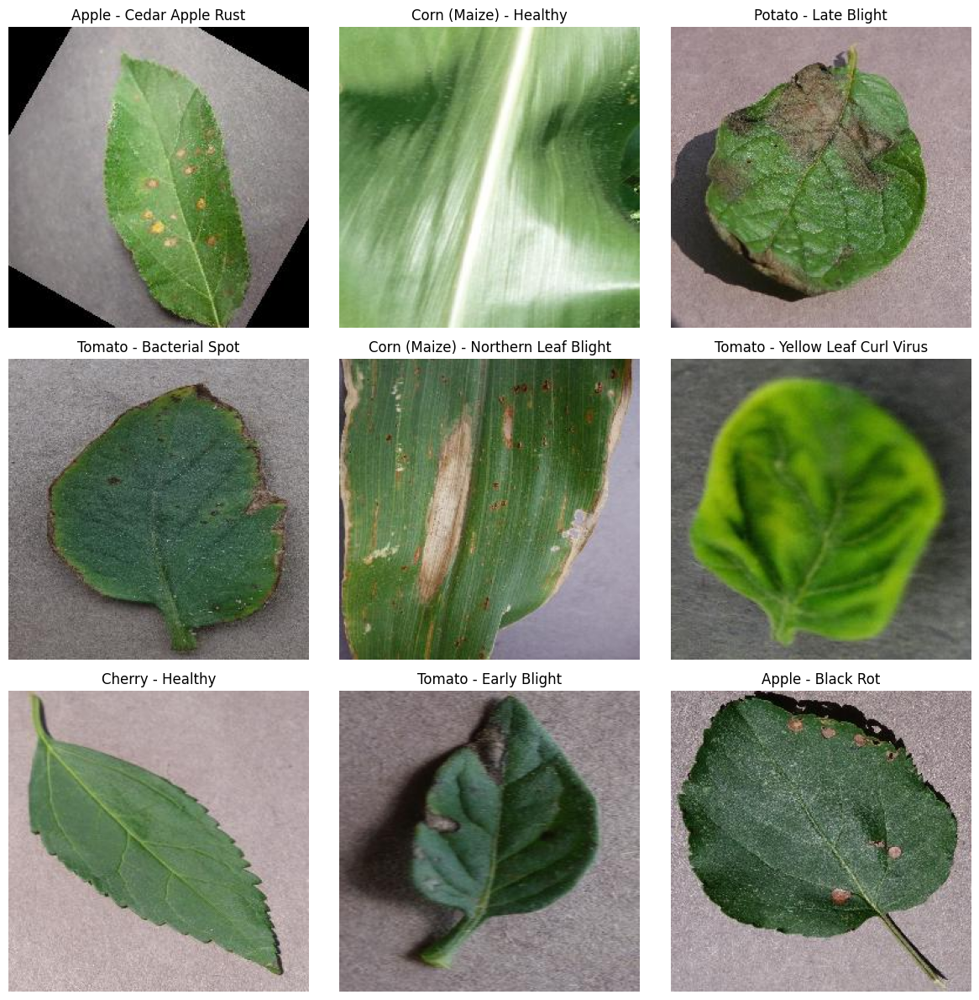

In [8]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

# Select 9 random classes
sample_classes = random.sample(classes, 9)

# Create a 3 × 3 grid
plt.figure(figsize=(12, 12))

for i, class_name in enumerate(sample_classes):

    # Path of the selected class
    class_path = os.path.join(train_path, class_name)

    # Get all images in that class
    image_files = os.listdir(class_path)

    # Select one random image
    image_name = random.choice(image_files)

    # Complete path of the image
    image_path = os.path.join(class_path, image_name)

    # Open the image
    image = Image.open(image_path)

    # Display the image
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
sample_info = []

for class_name in classes:
    class_path = os.path.join(train_path, class_name)

    # Take the first image from each class
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    # Open the image
    image = Image.open(image_path)

    sample_info.append({
        "Class": class_name,
        "Image": image_name,
        "Width": image.width,
        "Height": image.height,
        "Mode": image.mode,
        "Format": image.format
    })

image_info = pd.DataFrame(sample_info)

print(image_info)

                                  Class  \
0                    Apple - Apple Scab   
1                     Apple - Black Rot   
2              Apple - Cedar Apple Rust   
3                       Apple - Healthy   
4          Bell Pepper - Bacterial Spot   
5                 Bell Pepper - Healthy   
6                      Cherry - Healthy   
7               Cherry - Powdery Mildew   
8   Corn (Maize) - Cercospora Leaf Spot   
9            Corn (Maize) - Common Rust   
10               Corn (Maize) - Healthy   
11  Corn (Maize) - Northern Leaf Blight   
12                    Grape - Black Rot   
13         Grape - Esca (Black Measles)   
14                      Grape - Healthy   
15                  Grape - Leaf Blight   
16               Peach - Bacterial Spot   
17                      Peach - Healthy   
18                Potato - Early Blight   
19                     Potato - Healthy   
20                 Potato - Late Blight   
21                 Strawberry - Healthy   
22         

In [10]:
print("Unique image sizes:")
print(image_info[["Width", "Height"]].drop_duplicates())

print("\nImage modes:")
print(image_info["Mode"].value_counts())

print("\nImage formats:")
print(image_info["Format"].value_counts())

Unique image sizes:
   Width  Height
0    256     256

Image modes:
Mode
RGB    29
Name: count, dtype: int64

Image formats:
Format
JPEG    29
Name: count, dtype: int64


In [11]:
from PIL import Image
import os

total_images = 0
correct_size = 0
wrong_size = 0
rgb_images = 0
non_rgb_images = 0
corrupted_images = 0

wrong_size_files = []
non_rgb_files = []
corrupted_files = []

for class_name in classes:

    class_path = os.path.join(train_path, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        try:
            with Image.open(image_path) as image:

                total_images += 1


                if image.size == (256, 256):
                    correct_size += 1
                else:
                    wrong_size += 1
                    wrong_size_files.append(
                        (image_path, image.size)
                    )


                if image.mode == "RGB":
                    rgb_images += 1
                else:
                    non_rgb_images += 1
                    non_rgb_files.append(
                        (image_path, image.mode)
                    )

            
                image.verify()

        except Exception:
            corrupted_images += 1
            corrupted_files.append(image_path)


print("Total images checked:", total_images)
print("256 × 256 images:", correct_size)
print("Other size images:", wrong_size)
print("RGB images:", rgb_images)
print("Non-RGB images:", non_rgb_images)
print("Corrupted images:", corrupted_images)

Total images checked: 53690
256 × 256 images: 53690
Other size images: 0
RGB images: 53690
Non-RGB images: 0
Corrupted images: 1


In [12]:
class_counts = []

for class_name in classes:
    class_path = os.path.join(train_path, class_name)
    count = len(os.listdir(class_path))
    class_counts.append(count)

# Create a DataFrame
class_distribution = pd.DataFrame({
    "Class": classes,
    "Image Count": class_counts
})

class_distribution = class_distribution.sort_values(
    by="Image Count",
    ascending=False
)


print(class_distribution)

                                  Class  Image Count
0                    Apple - Apple Scab         2016
3                       Apple - Healthy         2008
5                 Bell Pepper - Healthy         1988
1                     Apple - Black Rot         1987
28      Tomato - Yellow Leaf Curl Virus         1961
20                 Potato - Late Blight         1939
18                Potato - Early Blight         1939
25                     Tomato - Healthy         1926
13         Grape - Esca (Black Measles)         1920
24                Tomato - Early Blight         1920
4          Bell Pepper - Bacterial Spot         1913
11  Corn (Maize) - Northern Leaf Blight         1908
9            Corn (Maize) - Common Rust         1907
12                    Grape - Black Rot         1888
10               Corn (Maize) - Healthy         1859
26                 Tomato - Late Blight         1851
16               Peach - Bacterial Spot         1838
6                      Cherry - Healthy       

In [13]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_PATH = "/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset"
assert os.path.isdir(BASE_PATH), "BASE_PATH is wrong"
print("Folders inside dataset:", os.listdir(BASE_PATH))


split_map = {
    d.lower(): d
    for d in os.listdir(BASE_PATH)
    if os.path.isdir(os.path.join(BASE_PATH, d))
}

def find_split(possible_names):
    for name in possible_names:
        if name in split_map:
            return os.path.join(BASE_PATH, split_map[name])
    raise FileNotFoundError(f"None of {possible_names} found. Present: {list(split_map.values())}")

train_path = find_split(["train"])
val_path   = find_split(["valid", "validation", "val"])
test_path  = find_split(["test"])

def list_classes(split_path):
    return sorted(
        d for d in os.listdir(split_path)
        if os.path.isdir(os.path.join(split_path, d))
    )

classes = list_classes(train_path)
assert list_classes(val_path) == classes, "Validation classes differ from train classes"
assert list_classes(test_path) == classes, "Test classes differ from train classes"

print("Train:", train_path)
print("Val  :", val_path)
print("Test :", test_path)
print("Number of classes:", len(classes))

Folders inside dataset: ['Val', 'Test', 'Train']
Train: /kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Train
Val  : /kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Val
Test : /kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Test
Number of classes: 29


In [14]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def count_images(folder):
    return sum(1 for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))

rows = []
for c in classes:
    rows.append({
        "Class": c,
        "Train": count_images(os.path.join(train_path, c)),
        "Validation": count_images(os.path.join(val_path, c)),
        "Test": count_images(os.path.join(test_path, c)),
    })

split_counts = pd.DataFrame(rows)
split_counts["Total"] = split_counts[["Train", "Validation", "Test"]].sum(axis=1)
split_counts["Train %"] = (split_counts["Train"] / split_counts["Total"] * 100).round(1)

print(split_counts.sort_values("Train", ascending=False).to_string(index=False))

print("\nTotals per split:")
print(split_counts[["Train", "Validation", "Test", "Total"]].sum())

non_image = sum(
    len(os.listdir(os.path.join(sp, c))) - count_images(os.path.join(sp, c))
    for sp in (train_path, val_path, test_path)
    for c in classes
)
print("\nNon-image files found:", non_image)

                              Class  Train  Validation  Test  Total  Train %
                 Apple - Apple Scab   2016         453    51   2520     80.0
                    Apple - Healthy   2008         451    51   2510     80.0
              Bell Pepper - Healthy   1988         447    50   2485     80.0
                  Apple - Black Rot   1987         447    50   2484     80.0
    Tomato - Yellow Leaf Curl Virus   1961         441    49   2451     80.0
               Potato - Late Blight   1939         436    49   2424     80.0
              Potato - Early Blight   1939         436    49   2424     80.0
                   Tomato - Healthy   1926         432    49   2407     80.0
       Grape - Esca (Black Measles)   1920         432    48   2400     80.0
              Tomato - Early Blight   1920         432    48   2400     80.0
       Bell Pepper - Bacterial Spot   1913         430    48   2391     80.0
Corn (Maize) - Northern Leaf Blight   1908         429    48   2385     80.0

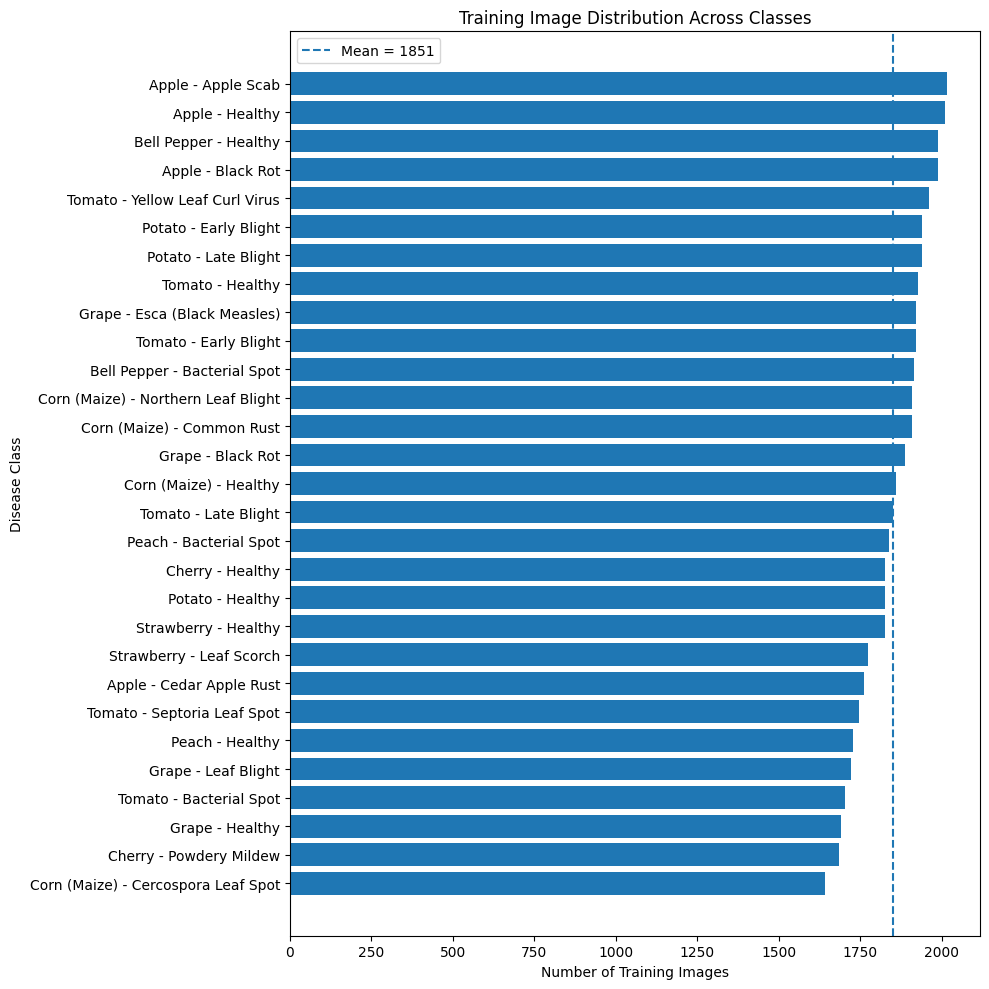

Max: 2016 | Min: 1642 | Imbalance ratio: 1.23


In [15]:
plot_df = split_counts.sort_values("Train")
mean_train = plot_df["Train"].mean()

plt.figure(figsize=(10, 10))
plt.barh(plot_df["Class"], plot_df["Train"])
plt.axvline(mean_train, linestyle="--", label=f"Mean = {mean_train:.0f}")
plt.xlabel("Number of Training Images")
plt.ylabel("Disease Class")
plt.title("Training Image Distribution Across Classes")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Max: {plot_df['Train'].max()} | Min: {plot_df['Train'].min()} | "
      f"Imbalance ratio: {plot_df['Train'].max() / plot_df['Train'].min():.2f}")

In [16]:
non_image_files = []
for split_name, split_path in [("Train", train_path), ("Val", val_path), ("Test", test_path)]:
    for c in classes:
        folder = os.path.join(split_path, c)
        for f in os.listdir(folder):
            if not f.lower().endswith(IMG_EXT):
                non_image_files.append(os.path.join(folder, f))

print("Non-image files:", len(non_image_files))
for p in non_image_files:
    print(p)

print("\nSample file names for class:", classes[0])
for split_name, split_path in [("Train", train_path), ("Val", val_path), ("Test", test_path)]:
    files = sorted(os.listdir(os.path.join(split_path, classes[0])))
    print(f"{split_name}: {files[:5]}")

Non-image files: 2
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Train/Tomato - Septoria Leaf Spot/.ipynb_checkpoints
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Test/Corn (Maize) - Cercospora Leaf Spot/.ipynb_checkpoints

Sample file names for class: Apple - Apple Scab
Train: ['00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG', '01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG', '01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_270deg.JPG', '01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_90deg.JPG', '01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_new30degFlipLR.JPG']
Val: ['00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_270deg.JPG', '00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_90deg.JPG', '00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_new30degFlipLR.JPG', '01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112_270deg.JPG', '0208f4eb-45a4-4399

In [17]:
from PIL import Image
from tqdm import tqdm

records = []
corrupted = []

for split_name, split_path in [("Train", train_path), ("Val", val_path), ("Test", test_path)]:
    for c in tqdm(classes, desc=split_name):
        folder = os.path.join(split_path, c)
        for f in os.listdir(folder):
            if not f.lower().endswith(IMG_EXT):
                continue
            fp = os.path.join(folder, f)
            try:
                with Image.open(fp) as img:
                    img.verify()
                with Image.open(fp) as img:
                    w, h = img.size
                    records.append((split_name, c, fp, w, h, img.mode, img.format))
            except Exception as e:
                corrupted.append((fp, str(e)))

image_info = pd.DataFrame(
    records, columns=["split", "class", "path", "width", "height", "mode", "format"]
)

print("Images scanned OK:", len(image_info))
print("Corrupted files  :", len(corrupted))
for item in corrupted[:10]:
    print(item)

print("\nImage sizes (top 10):")
print(image_info.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nColor modes:")
print(image_info["mode"].value_counts())
print("\nFormats:")
print(image_info["format"].value_counts())
print("\nImages per split:")
print(image_info["split"].value_counts())

Test: 100%|██████████| 29/29 [00:16<00:00,  1.76it/s]

Images scanned OK: 67111
Corrupted files  : 0

Image sizes (top 10):
width  height
256    256       67111
dtype: int64

Color modes:
mode
RGB    67111
Name: count, dtype: int64

Formats:
format
JPEG    67111
Name: count, dtype: int64

Images per split:
split
Train    53690
Val      12067
Test      1354
Name: count, dtype: int64


In [18]:
import re

def get_group_id(path):
    name = os.path.splitext(os.path.basename(path))[0]
    if "___" in name:
        return name.split("___")[0]
    return re.sub(r"_(\d+deg|new\d+deg\w*)$", "", name)

image_info["filename"] = image_info["path"].apply(os.path.basename)
image_info["group_id"] = image_info["path"].apply(get_group_id)
image_info["is_aug"] = image_info["filename"].str.contains("deg", case=False)

print("Files with '___' in name:", image_info["filename"].str.contains("___").sum(), "of", len(image_info))

print("\nShare of augmented-looking files per split (%):")
print(image_info.groupby("split")["is_aug"].mean().mul(100).round(1))

groups_by_split = {
    s: set(image_info.loc[image_info["split"] == s, "group_id"])
    for s in ["Train", "Val", "Test"]
}

print("\nFiles vs unique source images per split:")
for s, g in groups_by_split.items():
    n = (image_info["split"] == s).sum()
    print(f"{s}: {n} files from {len(g)} source images")

print("\nOverlap between splits:")
for a, b in [("Train", "Val"), ("Train", "Test"), ("Val", "Test")]:
    shared = groups_by_split[a] & groups_by_split[b]
    print(f"{a} vs {b}: {len(shared)} shared source images "
          f"({len(shared) / len(groups_by_split[b]) * 100:.1f}% of {b} source images)")

print("\nImages in each split whose source image also appears in Train:")
for s in ["Val", "Test"]:
    in_split = image_info["split"] == s
    leaked = in_split & image_info["group_id"].isin(groups_by_split["Train"])
    print(f"{s}: {leaked.sum()} of {in_split.sum()} ({leaked.sum() / in_split.sum() * 100:.1f}%)")

Files with '___' in name: 64727 of 67111

Share of augmented-looking files per split (%):
split
Test     27.8
Train    27.3
Val      27.4
Name: is_aug, dtype: float64

Files vs unique source images per split:
Train: 53690 files from 29989 source images
Val: 12067 files from 10238 source images
Test: 1354 files from 1338 source images

Overlap between splits:
Train vs Val: 6712 shared source images (65.6% of Val source images)
Train vs Test: 905 shared source images (67.6% of Test source images)
Val vs Test: 397 shared source images (29.7% of Test source images)

Images in each split whose source image also appears in Train:
Val: 8226 of 12067 (68.2%)
Test: 914 of 1354 (67.5%)


In [19]:
no_sep = image_info[~image_info["filename"].str.contains("___")]
print("Files without '___':", len(no_sep))
print(no_sep["split"].value_counts())
print("\nExamples:")
for f in no_sep["filename"].sample(10, random_state=42):
    print(f)

with_sep = image_info[image_info["filename"].str.contains("___")].copy()
stem = with_sep["filename"].apply(lambda n: os.path.splitext(n.split("___", 1)[1])[0])
with_sep["suffix"] = stem.str.extract(r"_([^_ ]+)$", expand=False).fillna("(none)")
print("\nSuffix types:")
print(with_sep["suffix"].value_counts().head(15))

classes_per_group = image_info.groupby("group_id")["class"].nunique()
print("\nUnique group_ids:", image_info["group_id"].nunique())
print("Groups spanning more than one class:", (classes_per_group > 1).sum())

print("\nFiles per group_id (group size : number of groups):")
print(image_info.groupby("group_id").size().value_counts().sort_index().head(10))

Files without '___': 2384
split
Train    1907
Val       429
Test       48
Name: count, dtype: int64

Examples:
RS_Rust 2012_flipLR.JPG
RS_Rust 2448.JPG
RS_Rust 2651_flipLR.JPG
RS_Rust 2630_flipLR.JPG
RS_Rust 1902_flipLR.JPG
RS_Rust 2284.JPG
RS_Rust 2732_flipLR.JPG
RS_Rust 1801_flipLR.JPG
RS_Rust 2477_flipLR.JPG
RS_Rust 2461_flipLR.JPG

Suffix types:
suffix
(none)             31495
flipLR              7153
180deg              6562
flipTB              5913
new30degFlipLR      3886
90deg               3430
270deg              3430
newPixel25          1243
newGRR               427
new30degFlipTB       427
newGGR               152
new90degFlipLR       152
new200degFlipTB      152
new90degFlipTB       152
new200degFlipLR      152
Name: count, dtype: int64

Unique group_ids: 33879
Groups spanning more than one class: 0

Files per group_id (group size : number of groups):
1     17686
2      7867
3      4440
4      1764
5      1335
6       360
8       275
15      152
Name: count, dtype: int64


In [20]:
SUFFIX_RE = re.compile(r"(?:_(?:flipLR|flipTB|\d+deg|new\w+))+$")

def parse_name(filename):
    stem = os.path.splitext(filename)[0]
    m = SUFFIX_RE.search(stem)
    suffix = m.group(0).lstrip("_") if m else ""
    base = stem[:m.start()] if m else stem
    group = base.split("___", 1)[0] if "___" in base else base
    return group, suffix

parsed = image_info["filename"].apply(parse_name)
image_info["group_id"] = parsed.str[0]
image_info["aug_suffix"] = parsed.str[1]
image_info["is_original"] = image_info["aug_suffix"] == ""
image_info = image_info.drop(columns=["is_aug"], errors="ignore")

no_sep = ~image_info["filename"].str.contains("___")
print("1. Classes holding files without '___':")
print(image_info.loc[no_sep, "class"].value_counts())
print("\nSuffixes in those files:")
print(image_info.loc[no_sep, "aug_suffix"].replace("", "(original)").value_counts())

print("\n2. All suffix types:")
print(image_info["aug_suffix"].replace("", "(original)").value_counts().to_string())

kw = image_info["filename"].str.contains(r"deg|flip|pixel|GRR|GGR", case=False, regex=True)
missed = image_info[kw & image_info["is_original"]]
print("\n3. Files with augmentation keywords but parsed as original:", len(missed))
for f in missed["filename"].head(5):
    print(f)

g = image_info.groupby("group_id")
print("\n4. Unique groups:", g.ngroups)
print("Groups spanning more than one class:", (g["class"].nunique() > 1).sum())
print("Groups with no original file:", (~g["is_original"].any()).sum())
print("\nFiles per group (group size : number of groups):")
print(g.size().value_counts().sort_index().head(15).to_string())

train_groups = set(image_info.loc[image_info["split"] == "Train", "group_id"])
print("\n5. Leakage recount with corrected groups:")
for s in ["Val", "Test"]:
    in_s = image_info["split"] == s
    leaked = in_s & image_info["group_id"].isin(train_groups)
    print(f"{s}: {leaked.sum()} of {in_s.sum()} files ({leaked.sum() / in_s.sum() * 100:.1f}%) share a group with Train")

summary = image_info.groupby("class").agg(
    Files=("path", "count"),
    Groups=("group_id", "nunique"),
    Originals=("is_original", "sum"),
)
print("\n6. Per class:")
print(summary.to_string())

1. Classes holding files without '___':
class
Corn (Maize) - Common Rust    2384
Name: count, dtype: int64

Suffixes in those files:
aug_suffix
(original)    1192
flipLR        1192
Name: count, dtype: int64

2. All suffix types:
aug_suffix
(original)         32688
flipLR              8345
180deg              6562
flipTB              5913
new30degFlipLR      3886
90deg               3430
270deg              3430
newPixel25          1243
new30degFlipTB       427
newGRR               427
newGGR               152
new90degFlipLR       152
new200degFlipTB      152
new90degFlipTB       152
new200degFlipLR      152

3. Files with augmentation keywords but parsed as original: 0

4. Unique groups: 32687
Groups spanning more than one class: 0
Groups with no original file: 0

Files per group (group size : number of groups):
1     15302
2      9059
3      4440
4      1764
5      1335
6       360
8       275
15      152

5. Leakage recount with corrected groups:
Val: 8568 of 12067 files (71.0%) sha

In [21]:
import numpy as np

SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   

orig_per_group = image_info[image_info["is_original"]].groupby("group_id").size()
multi = orig_per_group[orig_per_group > 1]
print("Groups with more than one original file:", len(multi))
for gid in multi.index:
    print(image_info.loc[image_info["group_id"] == gid, "filename"].tolist())

rng = np.random.RandomState(SEED)
group_to_split = {}
for c in classes:
    gids = sorted(image_info.loc[image_info["class"] == c, "group_id"].unique())
    rng.shuffle(gids)
    n = len(gids)
    n_train = int(round(TRAIN_FRAC * n))
    n_val = int(round(VAL_FRAC * n))
    for g in gids[:n_train]:
        group_to_split[g] = "train"
    for g in gids[n_train:n_train + n_val]:
        group_to_split[g] = "val"
    for g in gids[n_train + n_val:]:
        group_to_split[g] = "test"

manifest = image_info.rename(columns={"split": "old_split"}).copy()
manifest["new_split"] = manifest["group_id"].map(group_to_split)
assert manifest["new_split"].notna().all(), "Some files got no split"

keep = (manifest["new_split"] == "train") | manifest["is_original"]
print("\nCopies excluded from Val/Test:", (~keep).sum())
manifest = manifest[keep].reset_index(drop=True)

assert (manifest.groupby("group_id")["new_split"].nunique() == 1).all(), "A group is in two splits"
assert manifest.loc[manifest["new_split"] != "train", "is_original"].all(), "Copies in Val/Test"

counts = manifest.pivot_table(
    index="class", columns="new_split", values="path", aggfunc="count", fill_value=0
)[["train", "val", "test"]]
assert (counts > 0).all().all(), "A class is missing from a split"

print("\nFiles per split:")
print(manifest["new_split"].value_counts()[["train", "val", "test"]])

train_groups = set(manifest.loc[manifest["new_split"] == "train", "group_id"])
val_groups = set(manifest.loc[manifest["new_split"] == "val", "group_id"])
test_groups = set(manifest.loc[manifest["new_split"] == "test", "group_id"])
print("\nShared groups train/val:", len(train_groups & val_groups))
print("Shared groups train/test:", len(train_groups & test_groups))
print("Shared groups val/test:", len(val_groups & test_groups))

print("\nFiles per class and split:")
print(counts.to_string())

OUT = "/kaggle/working/split_manifest.csv"
manifest[["path", "class", "group_id", "is_original", "aug_suffix", "old_split", "new_split"]].to_csv(OUT, index=False)
print("\nSaved:", OUT)

Groups with more than one original file: 1
['af647b0e-db3a-459e-915c-4e522cb46c6c___R.S_HL 8101 copy sdf.jpg', 'af647b0e-db3a-459e-915c-4e522cb46c6c___R.S_HL 8101 copy.jpg']

Copies excluded from Val/Test: 10402

Files per split:
new_split
train    46902
val       4903
test      4904
Name: count, dtype: int64

Shared groups train/val: 0
Shared groups train/test: 0
Shared groups val/test: 0

Files per class and split:
new_split                            train  val  test
class                                                
Apple - Apple Scab                    1764   94    95
Apple - Black Rot                     1740   93    93
Apple - Cedar Apple Rust              1536   41    42
Apple - Healthy                       1753  247   246
Bell Pepper - Bacterial Spot          1682  150   149
Bell Pepper - Healthy                 1722  222   221
Cherry - Healthy                      1594  128   128
Cherry - Powdery Mildew               1472  158   158
Corn (Maize) - Cercospora Leaf Spot   1

In [22]:
import os
import pandas as pd

MANIFEST = "/kaggle/working/split_manifest.csv"
assert os.path.exists(MANIFEST), "split_manifest.csv not found. Run Cell 9 first."

manifest = pd.read_csv(MANIFEST)

print("Files per split:")
print(manifest["new_split"].value_counts())

groups_multi = (manifest.groupby("group_id")["new_split"].nunique() > 1).sum()
print("\nGroups present in more than one split:", groups_multi)

non_train = manifest[manifest["new_split"] != "train"]
print("Copies found in val/test:", (~non_train["is_original"]).sum())

counts = manifest.pivot_table(
    index="class", columns="new_split", values="path", aggfunc="count", fill_value=0
)[["train", "val", "test"]]
print("Classes missing from a split:", (counts == 0).any(axis=1).sum())

sample_paths = manifest["path"].sample(200, random_state=0)
print("Missing files among 200 sampled paths:", sum(not os.path.exists(p) for p in sample_paths))

print("\nFiles per class and split:")
print(counts.to_string())

Files per split:
new_split
train    46902
test      4904
val       4903
Name: count, dtype: int64

Groups present in more than one split: 0
Copies found in val/test: 0
Classes missing from a split: 0
Missing files among 200 sampled paths: 0

Files per class and split:
new_split                            train  val  test
class                                                
Apple - Apple Scab                    1764   94    95
Apple - Black Rot                     1740   93    93
Apple - Cedar Apple Rust              1536   41    42
Apple - Healthy                       1753  247   246
Bell Pepper - Bacterial Spot          1682  150   149
Bell Pepper - Healthy                 1722  222   221
Cherry - Healthy                      1594  128   128
Cherry - Powdery Mildew               1472  158   158
Corn (Maize) - Cercospora Leaf Spot   1436   77    77
Corn (Maize) - Common Rust            1668  179   179
Corn (Maize) - Healthy                1626  174   176
Corn (Maize) - Northern Leaf 

In [23]:
import os
import sys
import torch
import torchvision
import sklearn

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CPU cores   :", os.cpu_count())
print("CUDA (GPU) available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name   :", torch.cuda.get_device_name(0))
    print("GPU memory :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

Python      : 3.12.13
PyTorch     : 2.10.0+cu128
Torchvision : 0.25.0+cu128
Scikit-learn: 1.6.1
CPU cores   : 4
CUDA (GPU) available: True
GPU name   : Tesla T4
GPU memory : 15.6 GB


In [24]:
print("Original vs augmented/copy files in each split:")

summary = manifest.groupby(["new_split", "is_original"]).size().unstack(fill_value=0)

print(summary)

Original vs augmented/copy files in each split:
is_original  False  True 
new_split                
test             0   4904
train        24021  22881
val              0   4903


In [25]:
print("\nTraining files by class:")

train_summary = (
    manifest[manifest["new_split"] == "train"]
    .groupby(["class", "is_original"])
    .size()
    .unstack(fill_value=0)
)

print(train_summary.to_string())


Training files by class:
is_original                          False  True 
class                                            
Apple - Apple Scab                    1323    441
Apple - Black Rot                     1305    435
Apple - Cedar Apple Rust              1344    192
Apple - Healthy                        601   1152
Bell Pepper - Bacterial Spot           984    698
Bell Pepper - Healthy                  688   1034
Cherry - Healthy                       996    598
Cherry - Powdery Mildew                736    736
Corn (Maize) - Cercospora Leaf Spot   1077    359
Corn (Maize) - Common Rust             834    834
Corn (Maize) - Healthy                 813    813
Corn (Maize) - Northern Leaf Blight    966    690
Grape - Black Rot                      826    826
Grape - Esca (Black Measles)           715    968
Grape - Healthy                       1184    296
Grape - Leaf Blight                    753    753
Peach - Bacterial Spot                   0   1608
Peach - Healthy         

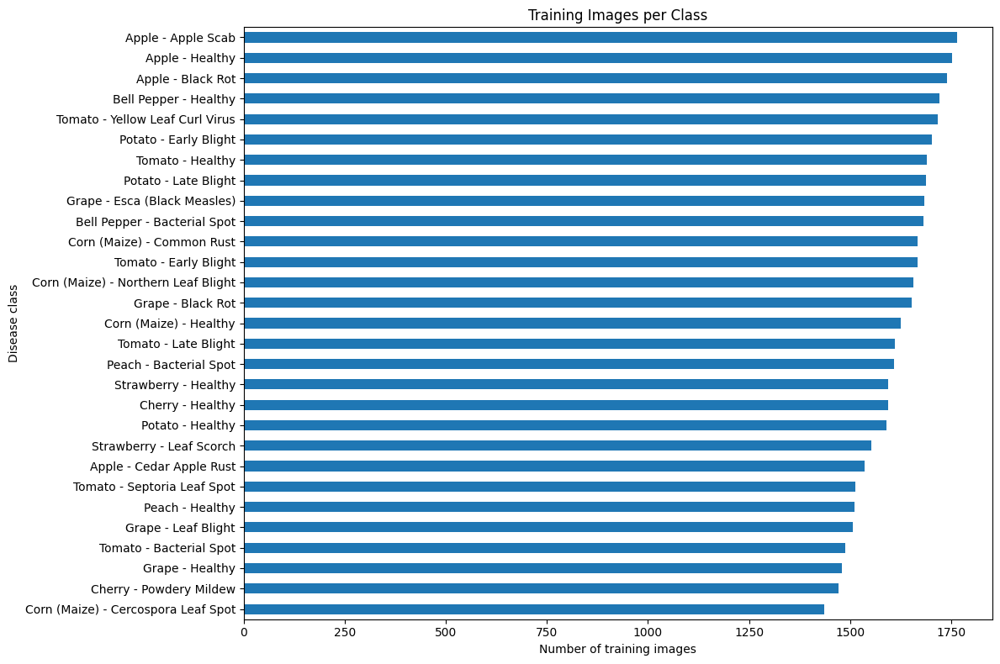

In [26]:
import matplotlib.pyplot as plt

class_counts = (
    manifest[manifest["new_split"] == "train"]
    .groupby("class")
    .size()
    .sort_values()
)

plt.figure(figsize=(12, 8))
class_counts.plot(kind="barh")

plt.xlabel("Number of training images")
plt.ylabel("Disease class")
plt.title("Training Images per Class")

plt.tight_layout()
plt.show()

In [27]:
import tensorflow as tf
import numpy as np
import pandas as pd
import json
import os


MANIFEST = "/kaggle/working/split_manifest.csv"
manifest = pd.read_csv(MANIFEST)

class_names = sorted(manifest["class"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

manifest["label"] = manifest["class"].map(class_to_index)

print("Number of classes:", len(class_names))
print("\nClass mapping:")

for name, index in class_to_index.items():
    print(index, "->", name)

Number of classes: 29

Class mapping:
0 -> Apple - Apple Scab
1 -> Apple - Black Rot
2 -> Apple - Cedar Apple Rust
3 -> Apple - Healthy
4 -> Bell Pepper - Bacterial Spot
5 -> Bell Pepper - Healthy
6 -> Cherry - Healthy
7 -> Cherry - Powdery Mildew
8 -> Corn (Maize) - Cercospora Leaf Spot
9 -> Corn (Maize) - Common Rust
10 -> Corn (Maize) - Healthy
11 -> Corn (Maize) - Northern Leaf Blight
12 -> Grape - Black Rot
13 -> Grape - Esca (Black Measles)
14 -> Grape - Healthy
15 -> Grape - Leaf Blight
16 -> Peach - Bacterial Spot
17 -> Peach - Healthy
18 -> Potato - Early Blight
19 -> Potato - Healthy
20 -> Potato - Late Blight
21 -> Strawberry - Healthy
22 -> Strawberry - Leaf Scorch
23 -> Tomato - Bacterial Spot
24 -> Tomato - Early Blight
25 -> Tomato - Healthy
26 -> Tomato - Late Blight
27 -> Tomato - Septoria Leaf Spot
28 -> Tomato - Yellow Leaf Curl Virus


In [28]:
LABEL_FILE = "/kaggle/working/class_names.json"

with open(LABEL_FILE, "w") as f:
    json.dump(class_names, f, indent=4)

print("Saved:", LABEL_FILE)


Saved: /kaggle/working/class_names.json


In [29]:
train_df = manifest[manifest["new_split"] == "train"].copy()
val_df   = manifest[manifest["new_split"] == "val"].copy()
test_df  = manifest[manifest["new_split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 46902
Validation: 4903
Test: 4904


In [30]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (128, 128)
Batch size: 32


In [31]:
def load_image(path, label):
    
    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [32]:
def create_dataset(df, shuffle=False):
    paths = df["path"].values
    labels = df["label"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [33]:
train_ds = create_dataset(train_df, shuffle=True)
val_ds   = create_dataset(val_df, shuffle=False)
test_ds  = create_dataset(test_df, shuffle=False)

print("TensorFlow datasets created successfully.")

I0000 00:00:1790763228.894767      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790763228.897740      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow datasets created successfully.


In [34]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [13 25  1 25 15 20 11  0 20 28]


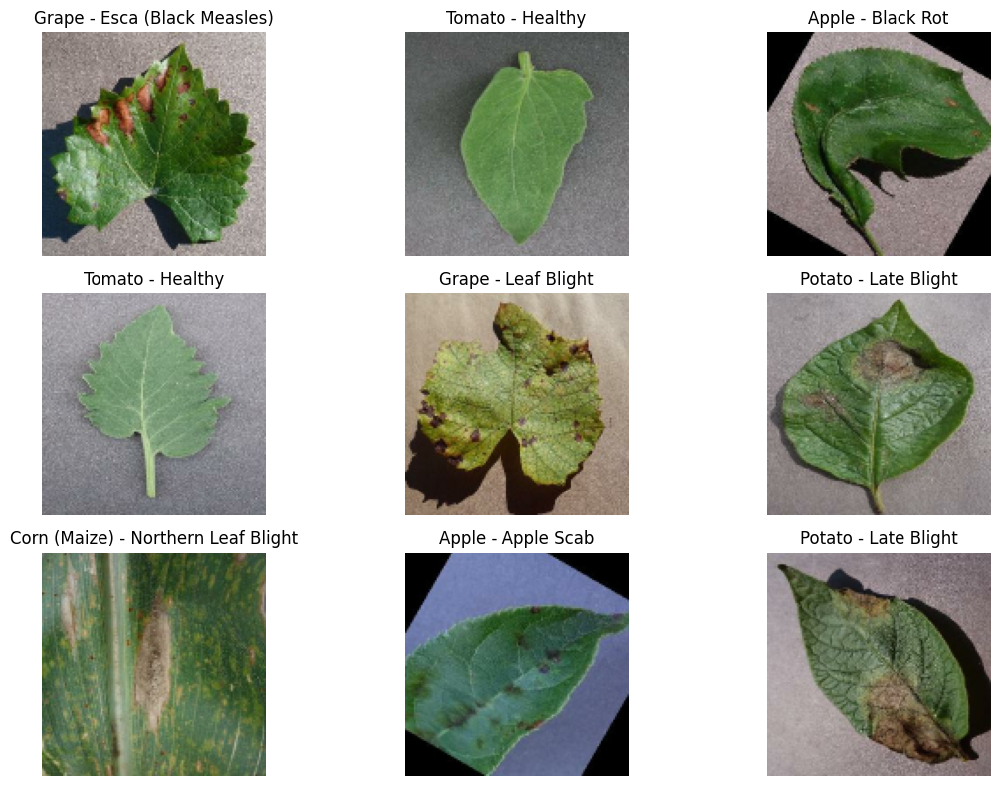

In [35]:
plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),

    tf.keras.layers.RandomRotation(
        factor=0.05
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.1,
        width_factor=0.1
    )
])

print("Data augmentation layer created.")

Data augmentation layer created.


In [37]:
images, labels = next(iter(train_ds))

augmented_images = data_augmentation(
    images,
    training=True
)

print("Original batch shape:", images.shape)
print("Augmented batch shape:", augmented_images.shape)

Original batch shape: (32, 128, 128, 3)
Augmented batch shape: (32, 128, 128, 3)


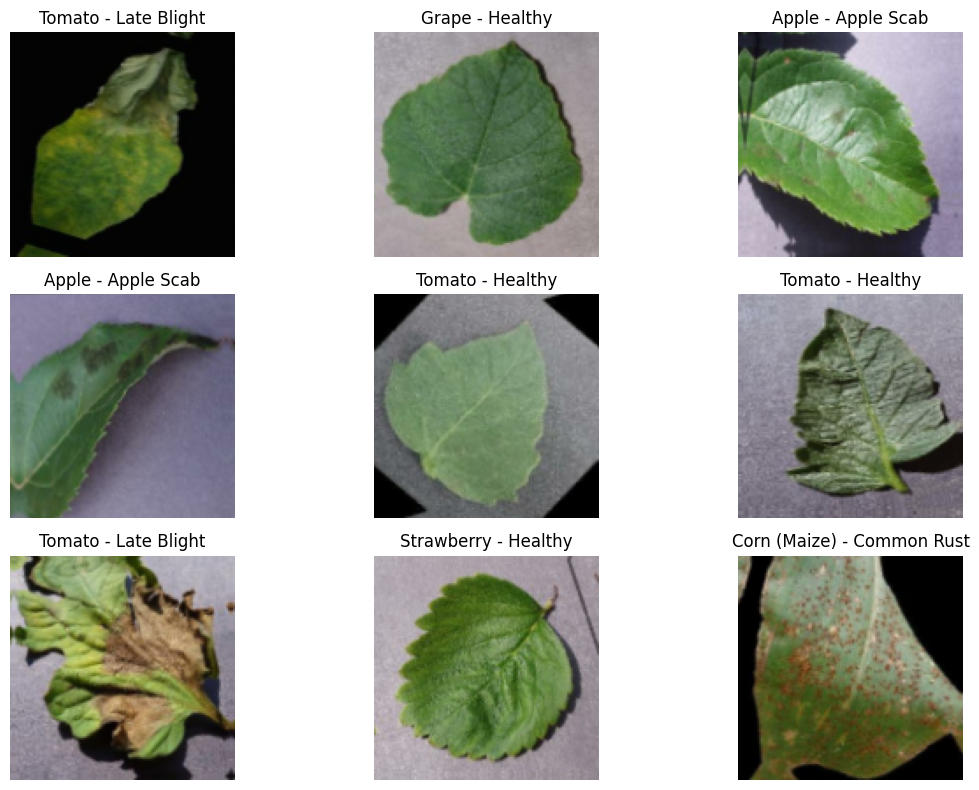

In [38]:
plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_images[i].numpy())
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
def augment_batch(images, labels):
    images = data_augmentation(images, training=True)
    return images, labels


train_ds_augmented = train_ds.map(
    augment_batch,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Training augmentation connected successfully.")

Training augmentation connected successfully.


In [40]:
NUM_CLASSES = len(class_names)

model = tf.keras.Sequential([
    
    # Input
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Block 1
    tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 4
    tf.keras.layers.Conv2D(256, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification head
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 426,973 (1.63 MB)

 Trainable params: 426,013 (1.63 MB)

 Non-trainable params: 960 (3.75 KB)

In [41]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [42]:
checkpoint_path = "/kaggle/working/best_crop_disease_model.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks created successfully.")

Callbacks created successfully.


In [43]:
history = model.fit(
    train_ds_augmented,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
   5/1466 ━━━━━━━━━━━━━━━━━━━━ 48s 33ms/step - accuracy: 0.0231 - loss: 4.0128    

I0000 00:00:1790763252.126776      74 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1466/1466 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.4452 - loss: 1.8772
Epoch 1: val_accuracy improved from None to 0.66592, saving model to /kaggle/working/best_crop_disease_model.keras

Epoch 1: finished saving model to /kaggle/working/best_crop_disease_model.keras
1466/1466 ━━━━━━━━━━━━━━━━━━━━ 125s 77ms/step - accuracy: 0.5901 - loss: 1.3315 - val_accuracy: 0.6659 - val_loss: 1.0458 - learning_rate: 0.0010
Epoch 2/15
1465/1466 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.7741 - loss: 0.6958
Epoch 2: val_accuracy improved from 0.66592 to 0.69508, saving model to /kaggle/working/best_crop_disease_model.keras

Epoch 2: finished saving model to /kaggle/working/best_crop_disease_model.keras
1466/1466 ━━━━━━━━━━━━━━━━━━━━ 99s 67ms/step - accuracy: 0.7995 - loss: 0.6172 - val_accuracy: 0.6951 - val_loss: 1.0361 - learning_rate: 0.0010
Epoch 3/15
1465/1466 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8473 - loss: 0.4692
Epoch 3: val_accuracy did not improve from 0.69508
1466/14

In [44]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

best_epoch = np.argmax(history.history["val_accuracy"]) + 1

print("Best epoch:", best_epoch)

print("Final training accuracy:",
      history.history["accuracy"][-1])

print("Final validation accuracy:",
      history.history["val_accuracy"][-1])

Best validation accuracy: 0.9714460372924805
Best epoch: 14
Final training accuracy: 0.9679757952690125
Final validation accuracy: 0.8500917553901672


In [45]:
import os

MODEL_PATH = "/kaggle/working/best_crop_disease_model.keras"

print("Model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print(
        "Model size:",
        os.path.getsize(MODEL_PATH) / (1024 * 1024),
        "MB"
    )

Model exists: True
Model size: 4.964862823486328 MB


In [46]:
best_model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Best model loaded successfully.")

Best model loaded successfully.


In [47]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFinal Test Results")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.9733 - loss: 0.0828

Final Test Results
Test Loss: 0.0827859491109848
Test Accuracy: 0.9732871055603027


In [48]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("True labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)
print("Correct predictions:", np.sum(y_true == y_pred))
print("Total predictions:", len(y_true))

True labels: (4904,)
Predicted labels: (4904,)
Correct predictions: 4773
Total predictions: 4904


In [49]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

                                     precision    recall  f1-score   support

                 Apple - Apple Scab     0.9894    0.9789    0.9841        95
                  Apple - Black Rot     0.9894    1.0000    0.9947        93
           Apple - Cedar Apple Rust     1.0000    1.0000    1.0000        42
                    Apple - Healthy     0.9563    0.9797    0.9679       246
       Bell Pepper - Bacterial Spot     0.9932    0.9732    0.9831       149
              Bell Pepper - Healthy     0.9733    0.9910    0.9821       221
                   Cherry - Healthy     0.9692    0.9844    0.9767       128
            Cherry - Powdery Mildew     1.0000    0.9873    0.9936       158
Corn (Maize) - Cercospora Leaf Spot     0.9091    0.9091    0.9091        77
         Corn (Maize) - Common Rust     0.9944    1.0000    0.9972       179
             Corn (Maize) - Healthy     1.0000    1.0000    1.0000       176
Corn (Maize) - Northern Leaf Blight     0.9589    0.9524    0.9556       14

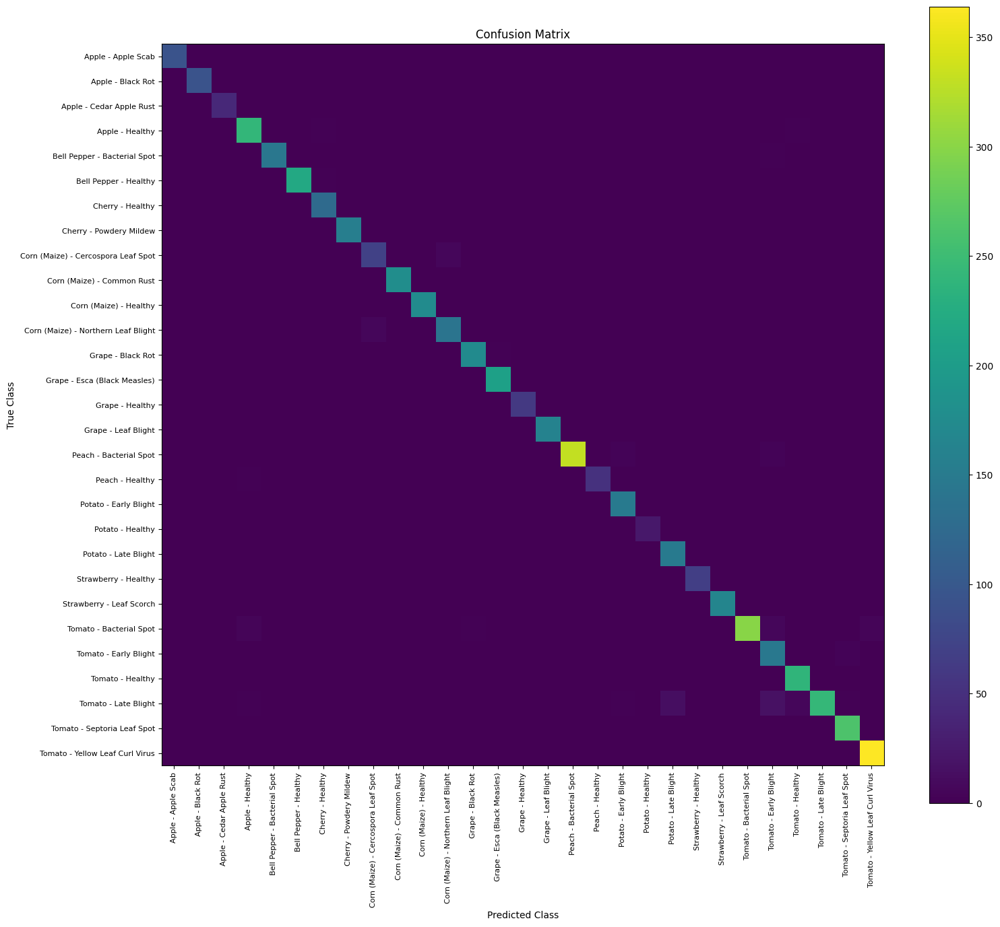

In [50]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    np.arange(len(class_names)),
    class_names,
    fontsize=8
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

cm = confusion_matrix(y_true, y_pred)

confusions = []

for true_idx in range(len(class_names)):
    for pred_idx in range(len(class_names)):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusions.append({
                "Actual": class_names[true_idx],
                "Predicted": class_names[pred_idx],
                "Wrong Predictions": cm[true_idx, pred_idx]
            })

confusion_df = pd.DataFrame(confusions)

confusion_df = confusion_df.sort_values(
    "Wrong Predictions",
    ascending=False
)

print("Top 15 confusion pairs:")
print(confusion_df.head(15).to_string(index=False))

Top 15 confusion pairs:
                             Actual                           Predicted  Wrong Predictions
               Tomato - Late Blight               Tomato - Early Blight                 16
               Tomato - Late Blight                Potato - Late Blight                 14
Corn (Maize) - Northern Leaf Blight Corn (Maize) - Cercospora Leaf Spot                  7
               Tomato - Late Blight                    Tomato - Healthy                  7
            Tomato - Bacterial Spot               Tomato - Early Blight                  7
Corn (Maize) - Cercospora Leaf Spot Corn (Maize) - Northern Leaf Blight                  6
            Tomato - Bacterial Spot                     Apple - Healthy                  5
            Tomato - Bacterial Spot     Tomato - Yellow Leaf Curl Virus                  5
             Peach - Bacterial Spot               Potato - Early Blight                  4
             Peach - Bacterial Spot               Tomato - Early B

In [52]:
original_train = manifest[
    (manifest["new_split"] == "train") &
    (manifest["is_original"] == True)
].copy()

original_counts = (
    original_train
    .groupby("class")
    .size()
    .sort_values()
)

print("Original training images:", len(original_train))
print("\nOriginal images per class:")
print(original_counts.to_string())

print("\nMinimum:", original_counts.min())
print("Maximum:", original_counts.max())

Original training images: 22881

Original images per class:
class
Potato - Healthy                        106
Apple - Cedar Apple Rust                192
Peach - Healthy                         252
Grape - Healthy                         296
Strawberry - Healthy                    319
Corn (Maize) - Cercospora Leaf Spot     359
Apple - Black Rot                       435
Apple - Apple Scab                      441
Cherry - Healthy                        598
Corn (Maize) - Northern Leaf Blight     690
Bell Pepper - Bacterial Spot            698
Potato - Early Blight                   700
Tomato - Early Blight                   700
Potato - Late Blight                    700
Cherry - Powdery Mildew                 736
Grape - Leaf Blight                     753
Strawberry - Leaf Scorch                776
Corn (Maize) - Healthy                  813
Grape - Black Rot                       826
Corn (Maize) - Common Rust              834
Grape - Esca (Black Measles)            968
Bell Peppe

In [53]:
train_counts = (
    train_df
    .groupby("class")
    .size()
    .sort_values()
)

print("Actual training images:", len(train_df))
print("\nActual training images per class:")
print(train_counts.to_string())

print("\nMinimum:", train_counts.min())
print("Maximum:", train_counts.max())

print(
    "\nImbalance ratio:",
    round(train_counts.max() / train_counts.min(), 2)
)

Actual training images: 46902

Actual training images per class:
class
Corn (Maize) - Cercospora Leaf Spot    1436
Cherry - Powdery Mildew                1472
Grape - Healthy                        1480
Tomato - Bacterial Spot                1489
Grape - Leaf Blight                    1506
Peach - Healthy                        1512
Tomato - Septoria Leaf Spot            1514
Apple - Cedar Apple Rust               1536
Strawberry - Leaf Scorch               1552
Potato - Healthy                       1590
Cherry - Healthy                       1594
Strawberry - Healthy                   1595
Peach - Bacterial Spot                 1608
Tomato - Late Blight                   1610
Corn (Maize) - Healthy                 1626
Grape - Black Rot                      1652
Corn (Maize) - Northern Leaf Blight    1656
Tomato - Early Blight                  1666
Corn (Maize) - Common Rust             1668
Bell Pepper - Bacterial Spot           1682
Grape - Esca (Black Measles)           1683
Potat

In [54]:
import numpy as np
import tensorflow as tf
from PIL import Image

def predict_single_image(image_path, model, class_names):
    
    image = Image.open(image_path).convert("RGB")

    
    image = image.resize(IMG_SIZE)

    
    image = np.array(image).astype("float32") / 255.0

    
    image = np.expand_dims(image, axis=0)

    
    predictions = model.predict(image, verbose=0)

    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index]

    return class_names[predicted_index], confidence


print("Single-image prediction function created successfully.")

Single-image prediction function created successfully.


In [55]:
import random

sample_path = random.choice(test_df["path"].tolist())

print("Selected image:")
print(sample_path)

print("\nActual class:")
print(test_df.loc[test_df["path"] == sample_path, "class"].iloc[0])

Selected image:
/kaggle/input/datasets/snikhilrao/crop-disease-detection-dataset/Plant Village Dataset/Train/Tomato - Yellow Leaf Curl Virus/aed111fb-7e72-4f86-a845-14bbcdd67328___UF.GRC_YLCV_Lab 01822.JPG

Actual class:
Tomato - Yellow Leaf Curl Virus


In [56]:
predicted_class, confidence = predict_single_image(
    sample_path,
    best_model,
    class_names
)

print("Actual class:   ", test_df.loc[test_df["path"] == sample_path, "class"].iloc[0])
print("Predicted class:", predicted_class)
print("Confidence:     ", f"{confidence * 100:.2f}%")

Actual class:    Tomato - Yellow Leaf Curl Virus
Predicted class: Tomato - Yellow Leaf Curl Virus
Confidence:      100.00%


In [57]:
import os

MODEL_PATH = "/kaggle/working/best_crop_disease_model.keras"
LABEL_PATH = "/kaggle/working/class_names.json"

print("Model exists:", os.path.exists(MODEL_PATH))
print("Labels exist:", os.path.exists(LABEL_PATH))

if os.path.exists(MODEL_PATH):
    print("Model size:",
          round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2),
          "MB")

if os.path.exists(LABEL_PATH):
    print("Labels size:",
          round(os.path.getsize(LABEL_PATH) / 1024, 2),
          "KB")

Model exists: True
Labels exist: True
Model size: 4.96 MB
Labels size: 0.85 KB
